In [1]:
import numpy as np
import pandas as pd
import shap
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import ks_2samp

In [2]:
# 1. Cargar el dataset
data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

In [3]:
# 2. Preprocesamiento
X = df.drop(columns=['target'])
y = df['target']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# 3. Entrenamiento del modelo
regressor = RandomForestRegressor(n_estimators=100, random_state=42)
regressor.fit(X_train_scaled, y_train)

RandomForestRegressor(random_state=42)

In [8]:
# 4. Evaluación
y_pred = regressor.predict(X_test_scaled)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 0.255169737347244
R2 Score: 0.8052747336256919


In [9]:
# 5. Optimización de hiperparámetros
grid_params = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}
grid_search = GridSearchCV(RandomForestRegressor(random_state=42), grid_params, cv=5, scoring='r2')
grid_search.fit(X_train_scaled, y_train)
print("\nMejores hiperparámetros:", grid_search.best_params_)


Mejores hiperparámetros: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 150}


In [10]:
# 6. Predicción con nuevos datos
new_data = np.array([[8.3252, 41.0, 6.984127, 1.023810, 322.0, 2.555556, 37.88, -122.23]])
new_data_scaled = scaler.transform(new_data)
prediction = grid_search.best_estimator_.predict(new_data_scaled)
print("\nPredicción para nuevo dato:", prediction[0])


Predicción para nuevo dato: 4.23940933333333


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [11]:
# 7. Interpretabilidad con SHAP
print("\n📊 Interpretabilidad con SHAP:")
explainer = shap.Explainer(regressor, X_test)
shap_values = explainer(X_test)


📊 Interpretabilidad con SHAP:


 96%|=================== | 3954/4128 [00:19<00:00]       

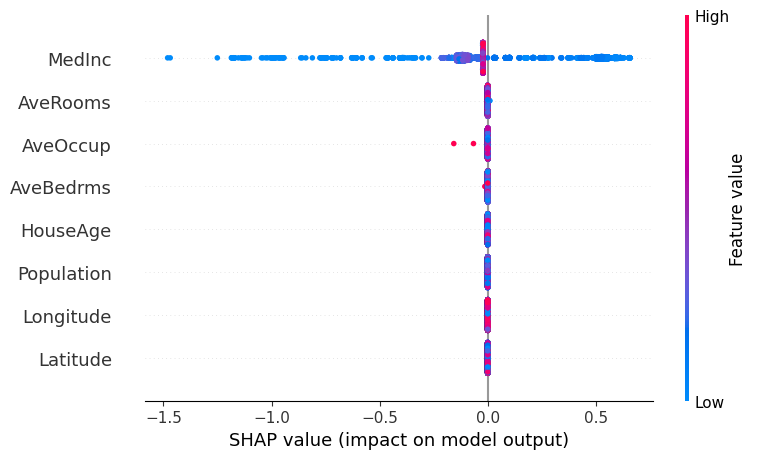

In [12]:
# Importancia global de características
shap.summary_plot(shap_values, X_test, feature_names=data.feature_names)

In [18]:
import shap

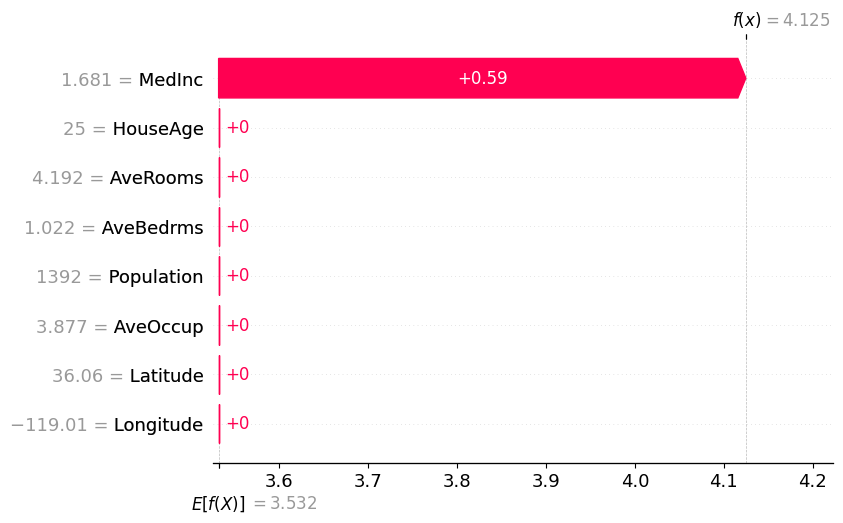

In [21]:
# Asegurarse de que shap_values es un array de Explanation objects
if not isinstance(shap_values, shap.Explanation):
    # Si es un array numpy, convertirlo a Explanation object
    shap_values = shap.Explanation(shap_values,
                                  base_values=explainer.expected_value,
                                  feature_names=data.feature_names)

# Visualización para una instancia específica
shap.initjs()

# Opción 1: Usando force_plot con la instancia específica
# shap.force_plot(explainer.expected_value,
#                shap_values[0],  # Valores SHAP para la primera instancia
#                feature_names=data.feature_names,
#                matplotlib=True)  # Si quieres mostrarlo en matplotlib en lugar de JS

# Opción 2: Usando waterfall plot (alternativa)
shap.plots.waterfall(shap_values[0])

# Opción 3: Usando force plot directamente del Explanation object
shap.plots.force(shap_values[0])

Interpretación de los resultados de SHAP (waterfall plot)

El gráfico waterfall (cascada) de SHAP muestra cómo cada característica contribuye a la predicción del modelo para una instancia específica. Vamos a desglosar cómo interpretarlo:

Estructura del gráfico waterfall

1. Valor base (base_value):

* Es el valor promedio de todas las predicciones del modelo (la predicción cuando no tenemos información de las características).

* Suele estar al principio del gráfico.

2. Flechas (barras) de características:

* Cada barra representa una característica y su contribución al valor final de la predicción.

* Las barras rojas empujan la predicción hacia arriba (aumentan el valor).

* Las barras azules empujan la predicción hacia abajo (disminuyen el valor).

3. Valor final (f(x)):

* Es el resultado de la predicción después de considerar todas las contribuciones.

* Aparece al final del gráfico.

Cómo interpretar cada elemento
* Eje Y: Muestra las características ordenadas por su magnitud de contribución (de mayor a menor impacto).

* Longitud de la barra: Indica la magnitud del impacto de esa característica.

* Dirección de la barra:

** Derecha (roja): Aumenta el valor de la predicción

** Izquierda (azul): Disminuye el valor de la predicción

Ejemplo práctico de interpretación
Si estamos prediciendo el precio de una casa y vemos:

1. Tamaño (sqft) = 1500 → +$50,000 (rojo)

* El tamaño de 1500 sqft aumenta el valor predicho en $50k

2. Edad (años) = 20 → -$10,000 (azul)

* Que la casa tenga 20 años reduce el valor predicho en $10k

3. Número de baños = 2 → +$5,000 (rojo)

* Tener 2 baños aumenta el valor predicho en $5k

El valor base podría ser 300,000 y el valor final(f(x)) sería: 300,000 +
50,000 − 50,000−10,000 + 5,000 = 5,000=345,000

Consejos para la interpretación

1. Enfócate en las características con mayor impacto: Las que tienen barras más largas son las más importantes para esa predicción.

2. Considera el contexto del valor base: Compara el valor final con el valor base para entender si la predicción es mayor o menor que el promedio.

3. Combinación de características: A veces el impacto no es lineal (interacciones entre características).

4. Escala de valores: Verifica si estás viendo valores logarítmicos o reales (especialmente en modelos de clasificación).